In [1]:
pip install torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 7.9 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import GCNConv, GATConv, GATv2Conv

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
DATA_DIR = Path("/kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data")
OUTPUT_DIR = Path("/kaggle/working/spatial_encoder_results")
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = DATA_DIR / "training_annual.npz"
VAL_FILE = DATA_DIR / "validation_annual.npz"
TEST_FILE = DATA_DIR / "testing_annual.npz"
METADATA_FILE = DATA_DIR / "annual_forecasting_metadata.json"
GRAPH_FILE = DATA_DIR / "static_spatial_graph_verified.pt"

SEEDS = [42, 123, 2023]
HIDDEN_DIM = 64
NUM_EPOCHS = 1000
LEARNING_RATE = 0.0005
NUM_FEATURES = 2

# Set this after checking the metadata / preprocessing convention:
# True  = missingness indicator value 1 means missing
# False = missingness indicator value 0 means missing
MISSING_INDICATOR_VALUE_FOR_MISSING = 1.0

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Output directory:", OUTPUT_DIR)

Device: cuda:0
Output directory: /kaggle/working/spatial_encoder_results


In [4]:
for path in [TRAIN_FILE, VAL_FILE, TEST_FILE, METADATA_FILE, GRAPH_FILE]:
    print(path.name, "exists:", path.exists())
    if not path.exists():
        raise FileNotFoundError(path)

train_npz = np.load(TRAIN_FILE)
val_npz = np.load(VAL_FILE)
test_npz = np.load(TEST_FILE)

print("Training NPZ keys:", train_npz.files)
print("Validation NPZ keys:", val_npz.files)
print("Testing NPZ keys:", test_npz.files)

metadata = json.load(open(METADATA_FILE, "r"))
print(json.dumps(metadata, indent=2)[:5000])

graph_obj = torch.load(GRAPH_FILE, map_location="cpu", weights_only=False)
print("Graph object type:", type(graph_obj))
if hasattr(graph_obj, "edge_index"):
    edge_index = graph_obj.edge_index.long()
elif isinstance(graph_obj, dict) and "edge_index" in graph_obj:
    edge_index = graph_obj["edge_index"].long()
else:
    raise ValueError("Could not locate edge_index in graph file.")

print("edge_index shape:", tuple(edge_index.shape))
print("Number of nodes:", int(edge_index.max().item()) + 1)
print("Number of directed edges:", edge_index.shape[1])

training_annual.npz exists: True
validation_annual.npz exists: True
testing_annual.npz exists: True
annual_forecasting_metadata.json exists: True
static_spatial_graph_verified.pt exists: True
Training NPZ keys: ['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years']
Validation NPZ keys: ['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years']
Testing NPZ keys: ['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years']
{
  "forecasting_task": "Annual one-year-ahead forecasting",
  "input_window_years": 10,
  "historical_period": "2000-2025",
  "training_target_years": [
    2010,
    2011,
    2012,
    2013,
    2014,
    2015,
    2016,
    2017
  ],
  "validation_target_years": [
    2018,
    2019,
    2020,
    2021,
    2022,
    2023
  ],
  "testing_target_years": [
    2024,
    2025
  ],
  "number_of_nodes": 5040,
  "number_of_input_features": 4,
  "input_features": [
    "Normalized rainfall",
    "Normalized maximum temperature",
  

In [5]:
# The revised dataset uses X arrays with shape:
# [samples, input_years, nodes, 4 features]
# Channels 0 and 1 are normalized rainfall and maximum temperature.
# Channels 2 and 3 are missingness indicators.

def get_array(npz_obj, candidate_names):
    for name in candidate_names:
        if name in npz_obj.files:
            return npz_obj[name], name
    raise KeyError(f"None of these keys were found: {candidate_names}. Available: {npz_obj.files}")

X_train_np, x_train_key = get_array(train_npz, ["X", "X_train", "x"])
X_val_np, x_val_key = get_array(val_npz, ["X", "X_val", "x"])
X_test_np, x_test_key = get_array(test_npz, ["X", "X_test", "x"])

print("Selected keys:", x_train_key, x_val_key, x_test_key)
print("X_train:", X_train_np.shape)
print("X_val:", X_val_np.shape)
print("X_test:", X_test_np.shape)

assert X_train_np.ndim == 4, "Expected X_train shape [samples, time, nodes, features]."
assert X_train_np.shape[-1] >= 4, "Expected four input channels."
assert np.isfinite(X_train_np).all(), "X_train contains non-finite values."
assert edge_index.shape[0] == 2
assert int(edge_index.max()) < X_train_np.shape[2]

print("Training input missingness indicator unique values:")
print("Rainfall:", np.unique(X_train_np[..., 2])[:10])
print("Temperature:", np.unique(X_train_np[..., 3])[:10])

Selected keys: X X X
X_train: (8, 10, 5040, 4)
X_val: (6, 10, 5040, 4)
X_test: (2, 10, 5040, 4)
Training input missingness indicator unique values:
Rainfall: [0. 1.]
Temperature: [0. 1.]


In [6]:
annual_snapshots = [X_train_np[0, t] for t in range(X_train_np.shape[1])]

for sample_idx in range(1, X_train_np.shape[0]):
    # Check the expected one-year sliding-window overlap.
    overlap_existing = np.stack(annual_snapshots[-(X_train_np.shape[1]-1):], axis=0)
    overlap_current = X_train_np[sample_idx, :-1, :, :]
    if not np.allclose(overlap_existing, overlap_current, equal_nan=True, atol=1e-5):
        raise ValueError(
            f"Training windows do not have the expected one-year overlap at sample {sample_idx}. "
            "Please inspect the sequence construction before proceeding."
        )
    annual_snapshots.append(X_train_np[sample_idx, -1])

annual_snapshots = np.stack(annual_snapshots, axis=0)
print("Unique annual snapshot tensor:", annual_snapshots.shape)
print("Expected shape: [training-input-years, nodes, 4]")

Unique annual snapshot tensor: (17, 5040, 4)
Expected shape: [training-input-years, nodes, 4]


In [7]:
# Feature channels 0 and 1: normalized rainfall and normalized maximum temperature.
# Missingness channels 2 and 3 identify which climate observations were imputed.

spatial_x_np = annual_snapshots[..., :2].astype(np.float32)
missing_indicators = annual_snapshots[..., 2:4]

missing_value = MISSING_INDICATOR_VALUE_FOR_MISSING
observed_mask_np = (missing_indicators != missing_value)

print("Spatial feature shape:", spatial_x_np.shape)
print("Observed rainfall fraction:", observed_mask_np[..., 0].mean())
print("Observed temperature fraction:", observed_mask_np[..., 1].mean())

if not np.isfinite(spatial_x_np).all():
    raise ValueError("Spatial feature tensor contains non-finite values.")

if observed_mask_np.sum() == 0:
    raise ValueError("No observed values found. Check the missingness indicator convention.")

# Convert to tensors. Shape: [years, nodes, 2].
spatial_x = torch.tensor(spatial_x_np, dtype=torch.float32, device=device)
observed_mask = torch.tensor(observed_mask_np, dtype=torch.bool, device=device)
edge_index = edge_index.to(device)

print("Tensor device:", spatial_x.device)
print("Graph nodes:", spatial_x.shape[1])
print("Graph edges:", edge_index.shape[1])

Spatial feature shape: (17, 5040, 2)
Observed rainfall fraction: 0.9396825396825397
Observed temperature fraction: 0.8796802054154995
Tensor device: cuda:0
Graph nodes: 5040
Graph edges: 40320


In [8]:
class GCNEncoder(nn.Module):
    def __init__(self, in_channels=2, hidden_channels=64, out_channels=2):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        reconstruction = self.conv2(h, edge_index)
        return reconstruction, h


class GATEncoder(nn.Module):
    def __init__(self, in_channels=2, hidden_channels=64, out_channels=2,
                 heads=4, dropout=0.0):
        super().__init__()
        self.conv1 = GATConv(
            in_channels, hidden_channels, heads=heads,
            concat=True, dropout=dropout, add_self_loops=False
        )
        self.conv2 = GATConv(
            hidden_channels * heads, out_channels, heads=1,
            concat=False, dropout=dropout, add_self_loops=False
        )

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        reconstruction = self.conv2(h, edge_index)
        return reconstruction, h


class GATv2Encoder(nn.Module):
    def __init__(self, in_channels=2, hidden_channels=64, out_channels=2,
                 heads=4, dropout=0.0):
        super().__init__()
        self.conv1 = GATv2Conv(
            in_channels, hidden_channels, heads=heads,
            concat=True, dropout=dropout, add_self_loops=False
        )
        self.conv2 = GATv2Conv(
            hidden_channels * heads, out_channels, heads=1,
            concat=False, dropout=dropout, add_self_loops=False
        )

    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index)
        h = F.relu(h)
        reconstruction = self.conv2(h, edge_index)
        return reconstruction, h


MODEL_CLASSES = {
    "GCN": GCNEncoder,
    "GAT": GATEncoder,
    "GATv2": GATv2Encoder
}

for model_name, model_class in MODEL_CLASSES.items():
    model = model_class().to(device)
    pred, emb = model(spatial_x[0], edge_index)
    print(model_name, "reconstruction:", tuple(pred.shape), "embedding:", tuple(emb.shape))

GCN reconstruction: (5040, 2) embedding: (5040, 64)
GAT reconstruction: (5040, 2) embedding: (5040, 256)
GATv2 reconstruction: (5040, 2) embedding: (5040, 256)


In [9]:
# Inspect missingness indicator values and frequencies

for feature_name, channel in [
    ("Rainfall", 2),
    ("Maximum Temperature", 3)
]:
    values, counts = np.unique(
        X_train_np[..., channel],
        return_counts=True
    )

    print(f"\n{feature_name} missingness indicator:")
    for value, count in zip(values, counts):
        print(f"Value {value}: {count:,} ({count / counts.sum() * 100:.2f}%)")


Rainfall missingness indicator:
Value 0.0: 378,880 (93.97%)
Value 1.0: 24,320 (6.03%)

Maximum Temperature missingness indicator:
Value 0.0: 354,405 (87.90%)
Value 1.0: 48,795 (12.10%)


In [10]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def masked_reconstruction_mse(prediction, target, mask):
    valid_pred = prediction[mask]
    valid_target = target[mask]
    if valid_pred.numel() == 0:
        raise ValueError("No valid entries available for reconstruction loss.")
    return F.mse_loss(valid_pred, valid_target)

print("Loss function and seed utility ready.")

Loss function and seed utility ready.


In [11]:
def train_spatial_encoder(model_name, seed):
    set_seed(seed)

    model = MODEL_CLASSES[model_name]().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = []
    start_time = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        optimizer.zero_grad()

        year_losses = []
        for year_idx in range(spatial_x.shape[0]):
            reconstruction, _ = model(spatial_x[year_idx], edge_index)
            loss_year = masked_reconstruction_mse(
                reconstruction,
                spatial_x[year_idx],
                observed_mask[year_idx]
            )
            year_losses.append(loss_year)

        loss = torch.stack(year_losses).mean()
        loss.backward()
        optimizer.step()

        epoch_loss = float(loss.detach().cpu())
        history.append(epoch_loss)

        if not np.isfinite(epoch_loss):
            raise FloatingPointError(
                f"Non-finite loss for {model_name}, seed {seed}, epoch {epoch}"
            )

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"{model_name} | seed={seed} | "
                f"epoch {epoch}/{NUM_EPOCHS} | reconstruction MSE={epoch_loss:.6f}"
            )

    training_time = time.time() - start_time

    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_seed_{seed}.pt"
    torch.save({
        "model_name": model_name,
        "seed": seed,
        "model_state_dict": model.state_dict(),
        "hidden_dim": HIDDEN_DIM,
        "learning_rate": LEARNING_RATE,
        "epochs": NUM_EPOCHS,
        "training_loss_history": history
    }, checkpoint_path)

    history_path = OUTPUT_DIR / f"{model_name}_seed_{seed}_loss.csv"
    pd.DataFrame({
        "epoch": np.arange(1, NUM_EPOCHS + 1),
        "reconstruction_mse": history
    }).to_csv(history_path, index=False)

    return model, history, training_time, checkpoint_path

In [12]:
all_histories = {}
training_records = []

for model_name in ["GCN", "GAT", "GATv2"]:
    for seed in SEEDS:
        print("\\n" + "=" * 75)
        print(f"Training {model_name} | seed={seed}")
        print("=" * 75)

        model, history, training_time, checkpoint_path = train_spatial_encoder(
            model_name, seed
        )

        all_histories[(model_name, seed)] = history
        training_records.append({
            "model": model_name,
            "seed": seed,
            "final_training_reconstruction_mse": history[-1],
            "minimum_training_reconstruction_mse": min(history),
            "epoch_of_minimum_training_mse": int(np.argmin(history) + 1),
            "training_time_seconds": training_time,
            "checkpoint": str(checkpoint_path)
        })

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

training_df = pd.DataFrame(training_records)
training_df.to_csv(OUTPUT_DIR / "spatial_encoder_training_summary.csv", index=False)
display(training_df)

\n===========================================================================
Training GCN | seed=42
GCN | seed=42 | epoch 1/1000 | reconstruction MSE=1.006736
GCN | seed=42 | epoch 100/1000 | reconstruction MSE=0.278836
GCN | seed=42 | epoch 200/1000 | reconstruction MSE=0.080202
GCN | seed=42 | epoch 300/1000 | reconstruction MSE=0.062762
GCN | seed=42 | epoch 400/1000 | reconstruction MSE=0.060131
GCN | seed=42 | epoch 500/1000 | reconstruction MSE=0.058489
GCN | seed=42 | epoch 600/1000 | reconstruction MSE=0.057308
GCN | seed=42 | epoch 700/1000 | reconstruction MSE=0.056360
GCN | seed=42 | epoch 800/1000 | reconstruction MSE=0.055548
GCN | seed=42 | epoch 900/1000 | reconstruction MSE=0.054843
GCN | seed=42 | epoch 1000/1000 | reconstruction MSE=0.054237
\n===========================================================================
Training GCN | seed=123
GCN | seed=123 | epoch 1/1000 | reconstruction MSE=0.870104
GCN | seed=123 | epoch 100/1000 | reconstruction MSE=0.211453
GCN |

,model,seed,final_training_reconstruction_mse,minimum_training_reconstruction_mse,epoch_of_minimum_training_mse,training_time_seconds,checkpoint
0,GCN,42,0.054237,0.054237,1000,49.158410,/kaggle/working/spatial_encoder_results/checkp...
1,GCN,123,0.053338,0.053338,1000,48.722835,/kaggle/working/spatial_encoder_results/checkp...
2,GCN,2023,0.053435,0.053435,1000,48.843828,/kaggle/working/spatial_encoder_results/checkp...
3,GAT,42,0.035158,0.035158,1000,93.677855,/kaggle/working/spatial_encoder_results/checkp...
4,GAT,123,0.046373,0.046373,1000,93.120988,/kaggle/working/spatial_encoder_results/checkp...
5,GAT,2023,0.031566,0.031566,1000,93.141552,/kaggle/working/spatial_encoder_results/checkp...
6,GATv2,42,0.035393,0.035393,1000,156.707026,/kaggle/working/spatial_encoder_results/checkp...
7,GATv2,123,0.030893,0.030893,1000,156.931575,/kaggle/working/spatial_encoder_results/checkp...
8,GATv2,2023,0.030591,0.030591,1000,156.943136,/kaggle/working/spatial_encoder_results/checkp...


In [13]:
evaluation_records = []

for model_name in ["GCN", "GAT", "GATv2"]:
    for seed in SEEDS:
        checkpoint_path = CHECKPOINT_DIR / f"{model_name}_seed_{seed}.pt"
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

        model = MODEL_CLASSES[model_name]().to(device)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        year_losses = []
        with torch.no_grad():
            for year_idx in range(spatial_x.shape[0]):
                reconstruction, _ = model(spatial_x[year_idx], edge_index)
                loss_year = masked_reconstruction_mse(
                    reconstruction,
                    spatial_x[year_idx],
                    observed_mask[year_idx]
                )
                year_losses.append(float(loss_year.cpu()))

        evaluation_records.append({
            "model": model_name,
            "seed": seed,
            "mean_training_year_reconstruction_mse": float(np.mean(year_losses)),
            "std_across_training_years": float(np.std(year_losses))
        })

        del model

evaluation_df = pd.DataFrame(evaluation_records)
evaluation_df.to_csv(OUTPUT_DIR / "spatial_encoder_reconstruction_by_seed.csv", index=False)
display(evaluation_df)

,model,seed,mean_training_year_reconstruction_mse,std_across_training_years
0,GCN,42,0.054231,0.013234
1,GCN,123,0.053334,0.012966
2,GCN,2023,0.053432,0.012968
3,GAT,42,0.035155,0.005760
4,GAT,123,0.046363,0.009097
5,GAT,2023,0.031561,0.004794
6,GATv2,42,0.035377,0.006319
7,GATv2,123,0.030890,0.004914
8,GATv2,2023,0.030584,0.004653


In [14]:
summary_df = (
    evaluation_df.groupby("model")["mean_training_year_reconstruction_mse"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "mean_reconstruction_mse",
        "std": "std_reconstruction_mse"
    })
    .sort_values("mean_reconstruction_mse")
)

summary_df.to_csv(OUTPUT_DIR / "spatial_encoder_reconstruction_summary.csv", index=False)
display(summary_df)

,model,mean_reconstruction_mse,std_reconstruction_mse
1,GATv2,0.032284,0.002683
0,GAT,0.037693,0.007721
2,GCN,0.053666,0.000492


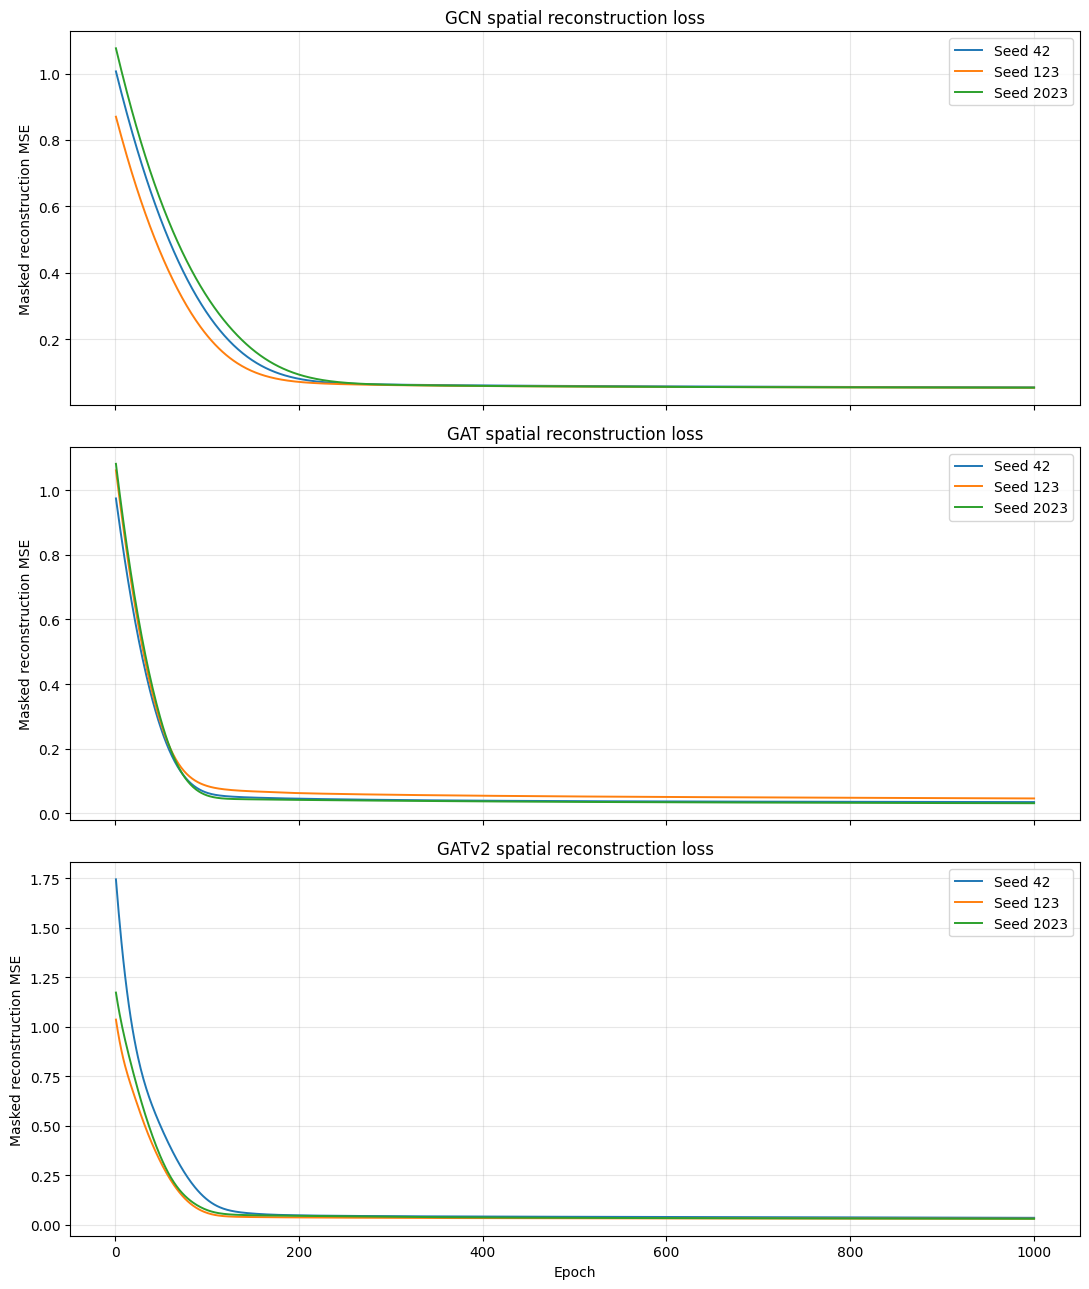

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)

for ax, model_name in zip(axes, ["GCN", "GAT", "GATv2"]):
    for seed in SEEDS:
        ax.plot(
            np.arange(1, NUM_EPOCHS + 1),
            all_histories[(model_name, seed)],
            label=f"Seed {seed}",
            linewidth=1.4
        )
    ax.set_title(f"{model_name} spatial reconstruction loss")
    ax.set_ylabel("Masked reconstruction MSE")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Epoch")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "spatial_encoder_loss_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
embedding_records = []

for model_name in ["GCN", "GAT", "GATv2"]:
    for seed in SEEDS:
        checkpoint_path = CHECKPOINT_DIR / f"{model_name}_seed_{seed}.pt"
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)

        model = MODEL_CLASSES[model_name]().to(device)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.eval()

        yearly_embeddings = []
        with torch.no_grad():
            for year_idx in range(spatial_x.shape[0]):
                _, embedding = model(spatial_x[year_idx], edge_index)
                yearly_embeddings.append(embedding.cpu().numpy())

        yearly_embeddings = np.stack(yearly_embeddings, axis=0)
        out_path = OUTPUT_DIR / f"{model_name}_seed_{seed}_training_embeddings.npy"
        np.save(out_path, yearly_embeddings)

        embedding_records.append({
            "model": model_name,
            "seed": seed,
            "embedding_shape": str(yearly_embeddings.shape),
            "file": str(out_path)
        })

        del model

embedding_df = pd.DataFrame(embedding_records)
embedding_df.to_csv(OUTPUT_DIR / "embedding_file_index.csv", index=False)
display(embedding_df)

,model,seed,embedding_shape,file
0,GCN,42,"(17, 5040, 64)",/kaggle/working/spatial_encoder_results/GCN_se...
1,GCN,123,"(17, 5040, 64)",/kaggle/working/spatial_encoder_results/GCN_se...
2,GCN,2023,"(17, 5040, 64)",/kaggle/working/spatial_encoder_results/GCN_se...
3,GAT,42,"(17, 5040, 256)",/kaggle/working/spatial_encoder_results/GAT_se...
4,GAT,123,"(17, 5040, 256)",/kaggle/working/spatial_encoder_results/GAT_se...
5,GAT,2023,"(17, 5040, 256)",/kaggle/working/spatial_encoder_results/GAT_se...
6,GATv2,42,"(17, 5040, 256)",/kaggle/working/spatial_encoder_results/GATv2_...
7,GATv2,123,"(17, 5040, 256)",/kaggle/working/spatial_encoder_results/GATv2_...
8,GATv2,2023,"(17, 5040, 256)",/kaggle/working/spatial_encoder_results/GATv2_...


In [17]:
print("Summary:")
display(summary_df)

print("\\nOutput files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUTPUT_DIR), f"({path.stat().st_size / 1024:.1f} KB)")

print("\\nSpatial encoder experiment completed.")

Summary:


,model,mean_reconstruction_mse,std_reconstruction_mse
1,GATv2,0.032284,0.002683
0,GAT,0.037693,0.007721
2,GCN,0.053666,0.000492


\nOutput files:
GAT_seed_123_loss.csv (23.4 KB)
GAT_seed_123_training_embeddings.npy (85680.1 KB)
GAT_seed_2023_loss.csv (23.5 KB)
GAT_seed_2023_training_embeddings.npy (85680.1 KB)
GAT_seed_42_loss.csv (23.5 KB)
GAT_seed_42_training_embeddings.npy (85680.1 KB)
GATv2_seed_123_loss.csv (23.5 KB)
GATv2_seed_123_training_embeddings.npy (85680.1 KB)
GATv2_seed_2023_loss.csv (23.5 KB)
GATv2_seed_2023_training_embeddings.npy (85680.1 KB)
GATv2_seed_42_loss.csv (23.5 KB)
GATv2_seed_42_training_embeddings.npy (85680.1 KB)
GCN_seed_123_loss.csv (23.4 KB)
GCN_seed_123_training_embeddings.npy (21420.1 KB)
GCN_seed_2023_loss.csv (23.4 KB)
GCN_seed_2023_training_embeddings.npy (21420.1 KB)
GCN_seed_42_loss.csv (23.4 KB)
GCN_seed_42_training_embeddings.npy (21420.1 KB)
checkpoints/GAT_seed_123.pt (19.7 KB)
checkpoints/GAT_seed_2023.pt (19.7 KB)
checkpoints/GAT_seed_42.pt (19.7 KB)
checkpoints/GATv2_seed_123.pt (25.9 KB)
checkpoints/GATv2_seed_2023.pt (25.9 KB)
checkpoints/GATv2_seed_42.pt (25.9 KB)


In [18]:
import os
import pandas as pd

RESULTS_DIR = "/kaggle/working/spatial_encoder_results"

print("FILES IN SPATIAL ENCODER RESULTS:\n")

for filename in sorted(os.listdir(RESULTS_DIR)):
    filepath = os.path.join(RESULTS_DIR, filename)
    if os.path.isfile(filepath):
        print(f"{filename:55s} {os.path.getsize(filepath):,} bytes")

print("\nEMBEDDING FILE INDEX:\n")

index_path = os.path.join(RESULTS_DIR, "embedding_file_index.csv")

if os.path.exists(index_path):
    embedding_index = pd.read_csv(index_path)
    print(embedding_index.to_string(index=False))
else:
    print("Embedding index not found.")

FILES IN SPATIAL ENCODER RESULTS:

GAT_seed_123_loss.csv                                   24,010 bytes
GAT_seed_123_training_embeddings.npy                    87,736,448 bytes
GAT_seed_2023_loss.csv                                  24,104 bytes
GAT_seed_2023_training_embeddings.npy                   87,736,448 bytes
GAT_seed_42_loss.csv                                    24,093 bytes
GAT_seed_42_training_embeddings.npy                     87,736,448 bytes
GATv2_seed_123_loss.csv                                 24,112 bytes
GATv2_seed_123_training_embeddings.npy                  87,736,448 bytes
GATv2_seed_2023_loss.csv                                24,067 bytes
GATv2_seed_2023_training_embeddings.npy                 87,736,448 bytes
GATv2_seed_42_loss.csv                                  24,054 bytes
GATv2_seed_42_training_embeddings.npy                   87,736,448 bytes
GCN_seed_123_loss.csv                                   23,973 bytes
GCN_seed_123_training_embeddings.npy        